# Information Field Theory and Automatic GP Kernel Discovery for Radiocarbon

Cosmic-ray $^{14}\mathrm{C}$ production fluctuates continuously across solar cycles, grand minima, and geomagnetic excursions alongside impulsive solar energetic particle spikes. Rather than fixing an *ad hoc* smoothing spline or single Gaussian-process (GP) covariance kernel by hand, `ticktack.fields` adapts the **Information Field Theory** (IFT; Enßlin, Frommert & Kitaura 2009; Edenhofer et al. 2024) and empirical-Bayes evidence framework of [`virgil`](https://github.com/benjaminpope/virgil) (MacKay 1992) to 1D carbon-box inverse problems.

Throughout this notebook we bridge IFT and GP terminology directly: a latent cosmic-ray fluctuation $\delta q(t)$ is an IFT **signal field**; its stationary GP kernel covariance on a padded 1D grid is diagonalized by the orthonormal Type-II discrete cosine transform (DCT-II) into a **power spectrum** $S(\omega)$; non-centred standard-normal latents $z \sim \mathcal{N}(0, I_N)$ act as **standardized excitations** mapped via $\eta = C^\top(\sqrt{S(\boldsymbol{\phi})} \odot z)$; the exact GP posterior mean $\hat{z} = (I + J^\top J)^{-1}J^\top \tilde{d}$ is the **Wiener filter**; and the marginal log-likelihood $\ln Z(\boldsymbol{\phi})$ is the log **partition function** used both to rank competing spectral families and to audit laboratory uncertainties via MacKay's `error_scale` diagnostic.

## 1. Reflecting-Boundary DCT-II Signal Fields and Shared Excitations

Periodic Fourier bases force $\eta(t_{\mathrm{start}}) = \eta(t_{\mathrm{end}})$, injecting wrap-around ringing whenever secular radiocarbon trends cross the window edges. Diagonalizing the 1D Neumann discrete Laplacian via the orthonormal DCT-II imposes natural reflecting boundary conditions ($\partial_t \eta = 0$) while preserving exact $O(N \log N)$ spectral synthesis. Below we draw a single bank of standardized excitations $z \sim \mathcal{N}(0, I_N)$ and pass those identical random numbers through three composable `SpectralKernel` priors—a rough Ornstein–Uhlenbeck (`order=1`) continuum, a smoother Matérn-3/2 (`order=2`) continuum, and a composite `MaternSpectrum + QuasiPeriodicSpectrum` encoding an 11-year Schwabe solar cycle.

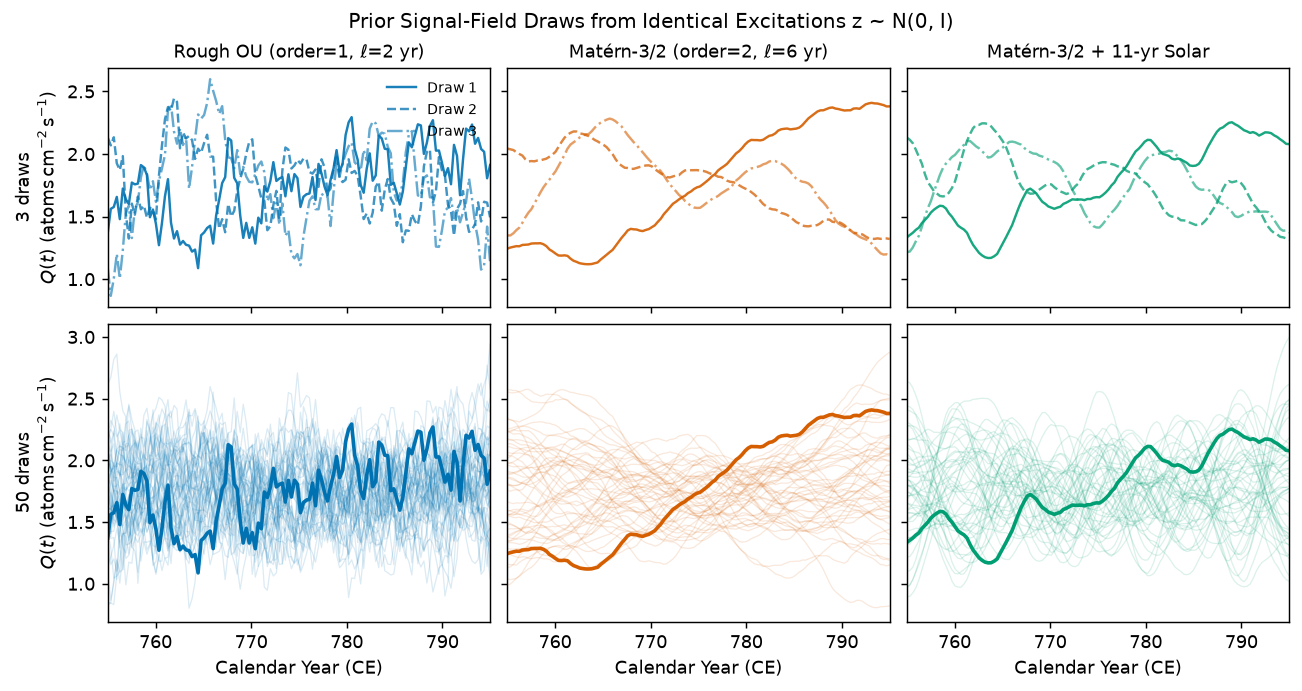

In [1]:
import jax
import jax.numpy as jnp
import matplotlib.pyplot as plt
import numpy as np
import ticktack as tt
from ticktack.fields import (
    GaussianField, MaternSpectrum, QuasiPeriodicSpectrum, dct_laplacian_eigenvalues,
    evidence_grid, plot_evidence_grid, plot_field_draws, predict_field_d14c, select_gp_kernel,
)

z0 = jnp.zeros(128)
prior_fields = {
    "Rough OU (order=1, ℓ=2 yr)": GaussianField(z0, 755.0, 795.0, kernel=MaternSpectrum(0.28, 2.0, order=1.0)),
    "Matérn-3/2 (order=2, ℓ=6 yr)": GaussianField(z0, 755.0, 795.0, kernel=MaternSpectrum(0.28, 6.0, order=2.0)),
    "Matérn-3/2 + 11-yr Solar": GaussianField(
        z0, 755.0, 795.0, kernel=MaternSpectrum(0.16, 8.0, order=2.0) + QuasiPeriodicSpectrum(0.22, 11.0, 5.0)
    ),
}
fig, _ = plot_field_draws(prior_fields, jax.random.PRNGKey(42), title="Prior Signal-Field Draws from Identical Excitations z ~ N(0, I)")

## 2. Empirical-Bayes $(\sigma, \ell)$ Log-Evidence Surface on the 775 CE Catalogue

Because the carbon-box ODE and seasonal tree-ring window quadrature are linear in $\delta q(t)$, `evidence_grid` precomputes the exact `DCTResponseOperator` once for all 28 Northern and Southern Hemisphere series in the bundled `775CE` catalogue (using the 22-box `Brehm21` carbon cycle, a parametric `MiyakeSpike`, and exact QR marginalization over global and per-laboratory $\Delta^{14}\mathrm{C}$ offsets). Evaluating the exact log partition function $\ln Z(\sigma, \ell)$ across an $8 \times 8$ logarithmic grid then reduces to rescaling precomputed DCT columns, revealing a well-localized empirical-Bayes peak where data fidelity balances the MacKay Occam determinant $-\frac{1}{2}\sum_k \ln(1 + s_k^2)$.

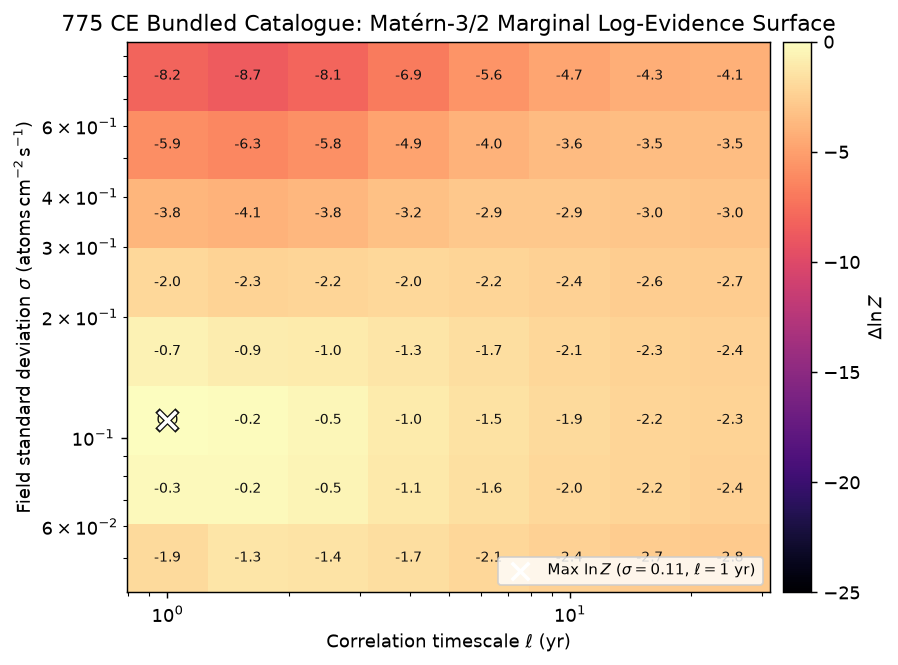

In [2]:
cbm = tt.load_preset("Brehm21")
dataset = tt.load_bundled_event("775CE")
spike_init = tt.MiyakeSpike(t_start=774.4, duration=0.5, fluence=6.4)

sigmas = jnp.geomspace(0.05, 0.80, 8)
lengths_yr = jnp.geomspace(1.0, 25.0, 8)
grid = evidence_grid(cbm, dataset, sigmas, lengths_yr, order=2.0, extra_production=spike_init)
fig, _ = plot_evidence_grid(grid, title="775 CE Bundled Catalogue: Matérn-3/2 Marginal Log-Evidence Surface")

## 3. Automatic Multi-Kernel Discovery and MacKay Error-Scale Audit

Rather than restricting attention to a single Matérn order on a coarse grid, `select_gp_kernel` optimizes hyperparameter vectors $\boldsymbol{\phi}$ continuously via multi-start BFGS using exact analytical JAX gradients across all seven built-in spectral families—including continuous-order Matérn (`learn_order=True`), composite `matern32_plus_solar`, and a non-parametric NIFTy-style `correlated_field` power spectrum—and ranks them by the Laplace hyper-evidence $\ln \mathcal{Z}_{\mathrm{hyper}}$ so higher-dimensional spectral families pay an explicit curvature Occam penalty. On the winning fit, MacKay's (1992) fixed-point `error_scale` $s = \sqrt{\chi^2 / (N_{\mathrm{eff}} - \gamma)}$ diagnoses whether the quoted laboratory uncertainties are slightly conservative ($s < 1$) or understated ($s > 1$).

In [3]:
selection = select_gp_kernel(
    cbm,
    dataset,
    extra_production=spike_init,
    multi_start=3,
    rng_key=jax.random.PRNGKey(7),
)
print(selection.format_table())

Rank Kernel                  d   ln Z(phi)  ln Z_hyper     dlnZ   Weight   gamma        BIC
-------------------------------------------------------------------------------------------
1    matern12                2     -733.60     -734.85    +0.00    0.196    2.06    1478.70
2    continuous_matern       3     -733.69     -734.99    -0.13    0.171    1.97    1484.61
3    squared_exp             2     -733.61     -735.00    -0.15    0.169    2.08    1478.70
4    matern32                2     -733.71     -735.09    -0.24    0.154    1.94    1478.91
5    correlated_field        6     -733.45     -735.17    -0.32    0.143    2.04    1501.37
6    matern52                2     -733.77     -735.34    -0.49    0.120    1.86    1479.04
7    matern32_plus_solar     5     -733.74     -736.28    -1.43    0.047    2.73    1496.21
-------------------------------------------------------------------------------------------
Selected kernel : matern12 (sigma=0.0541, length_yr=1.7, order=1)
MacKay s_error

## 4. Posterior Cosmic-Ray Production Field and Learned Power Spectrum

From the selected empirical-Bayes model, `select_gp_kernel` draws 200 exact Wiener posterior realizations $z^{(m)} = \hat{z} + (I + J^\top J)^{-1/2}\epsilon^{(m)}$ via economy SVD without forming an $N \times N$ covariance matrix. Below we plot the inferred ambient production rate $Q_{\mathrm{field}}(t) = q_0 + \delta q(t)$ (excluding the impulsive 774.4 CE `MiyakeSpike` so the decadal solar modulation is clearly resolved) alongside the learned DCT-II power spectrum $S(\omega)$ as a function of angular frequency $\omega_j = \sqrt{\lambda_j}$.

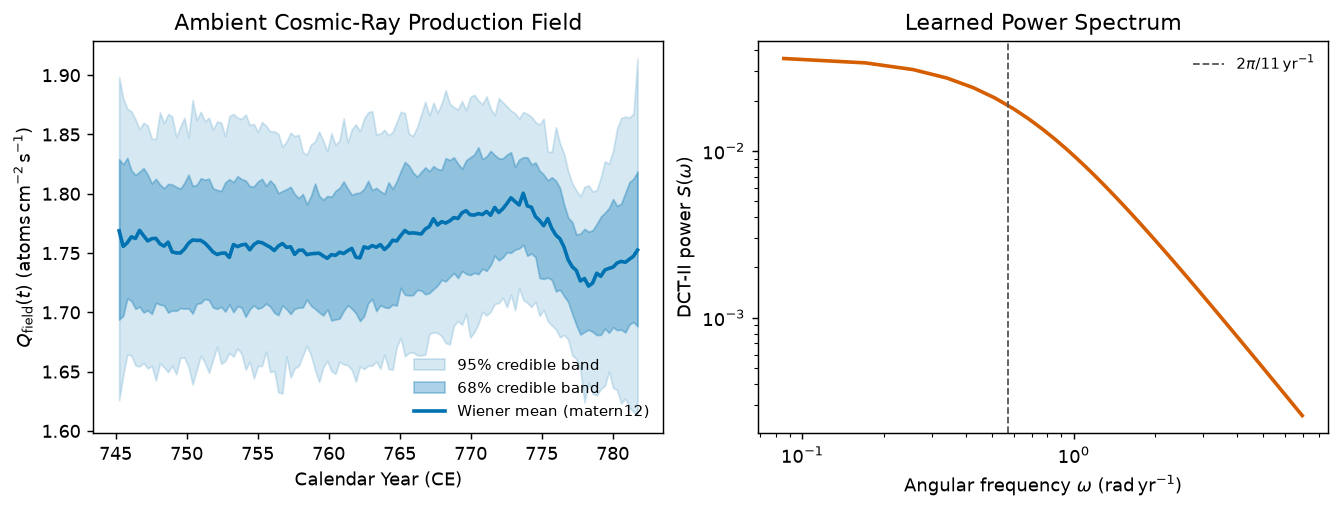

In [4]:
t_grid = np.asarray(selection.t_grid)
q_draws = np.asarray(selection.posterior_q)
q_med, q_lo1, q_hi1, q_lo2, q_hi2 = np.percentile(q_draws, [50.0, 16.0, 84.0, 2.5, 97.5], axis=0)
omega = np.sqrt(np.asarray(dct_laplacian_eigenvalues(t_grid.size, float(t_grid[1] - t_grid[0]))))[1:]
spec_pos = np.asarray(selection.posterior_spectrum)[1:]

fig, axes = plt.subplots(1, 2, figsize=(10.2, 3.8), constrained_layout=True)
axes[0].fill_between(t_grid, q_lo2, q_hi2, color="#0072B2", alpha=0.16, label="95% credible band")
axes[0].fill_between(t_grid, q_lo1, q_hi1, color="#0072B2", alpha=0.32, label="68% credible band")
axes[0].plot(t_grid, q_med, color="#0072B2", lw=2.0, label=f"Wiener mean ({selection.best_name})")
axes[0].set(xlabel="Calendar Year (CE)", ylabel=r"$Q_{\mathrm{field}}(t)$ ($\mathrm{atoms\,cm^{-2}\,s^{-1}}$)", title="Ambient Cosmic-Ray Production Field")
axes[0].legend(frameon=False, fontsize=8.5)
axes[1].loglog(omega, spec_pos, color="#D55E00", lw=2.0)
axes[1].axvline(2.0 * np.pi / 11.0, color="#555555", ls="--", lw=1.0, label=r"$2\pi / 11\,\mathrm{yr}^{-1}$")
axes[1].set(xlabel=r"Angular frequency $\omega$ ($\mathrm{rad\,yr^{-1}}$)", ylabel=r"DCT-II power $S(\omega)$", title="Learned Power Spectrum")
axes[1].legend(frameon=False, fontsize=8.5)

## 5. Hemispheric Tropospheric $\Delta^{14}\mathrm{C}$ Fit and Standardized Residuals

Finally, we propagate the jointly inferred `MiyakeSpike`, ambient IFT production field, and MAP hierarchical laboratory calibration offsets forward through the 22-box `Brehm21` carbon cycle into continuous Northern and Southern Hemisphere tropospheric $\Delta^{14}\mathrm{C}(t)$ trajectories. Because every tree-ring measurement is a direct scalar time-series datum, plotting all 28 series with their seasonal growth windows and standardized z-score residuals $(d_i - m_i) / \sigma_i$ displays the full data–model comparison directly across time without requiring a separate interferometric correlation scatter plot.

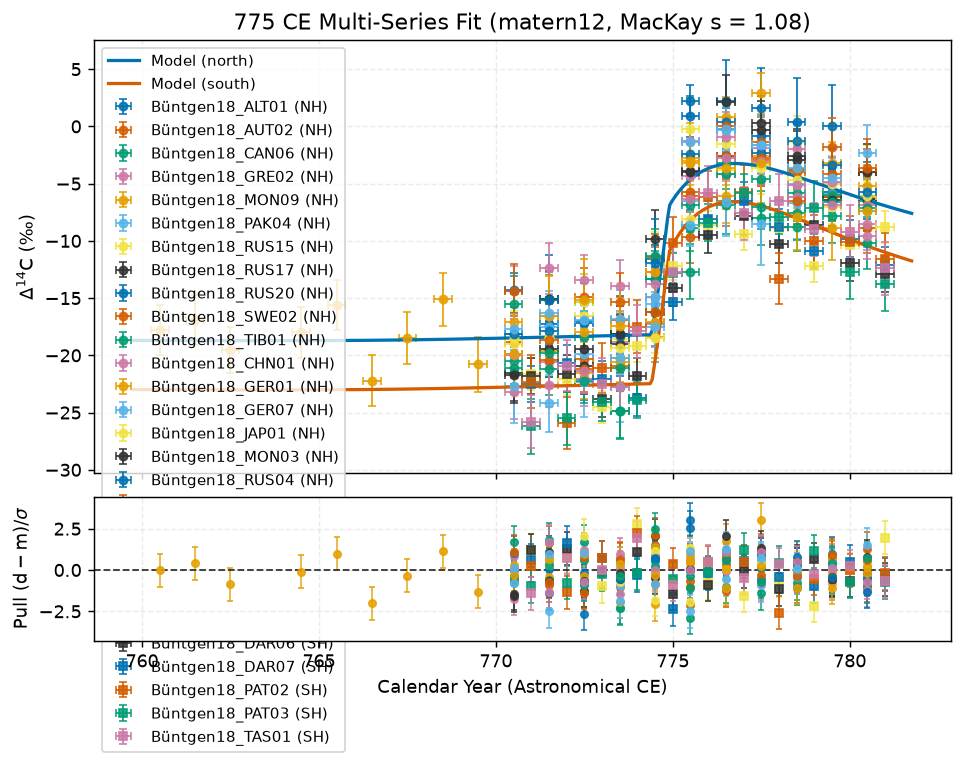

In [5]:
fit = selection.best_result.fit
t_fine = jnp.linspace(dataset.time_span[0] - 0.5, dataset.time_span[1] + 0.5, 400)
d14c_curves = {
    "north": predict_field_d14c(fit, dataset, t_fine=t_fine, hemisphere="north"),
    "south": predict_field_d14c(fit, dataset, t_fine=t_fine, hemisphere="south"),
}
ring_pred = predict_field_d14c(fit, dataset)
fig, _ = tt.plot_d14c_fit(
    dataset,
    t_fine=t_fine,
    d14c_pred=d14c_curves,
    ring_pred=ring_pred,
    show_residuals=True,
    title=f"775 CE Multi-Series Fit ({selection.best_name}, MacKay s = {selection.error_scale_global:.2f})",
)

## Summary

By representing non-parametric cosmic-ray production variations as standardized excitations on a 1D reflecting-boundary DCT-II eigenbasis, `ticktack.fields` unifies `virgil`-style Information Field Theory with exact carbon-box linear algebra. Precomputing the DCT response operator turns 2D $(\sigma, \ell)$ evidence sweeps, continuous multi-start BFGS hyperparameter optimization, seven-family Bayesian kernel selection, economy-SVD posterior sampling, and MacKay's noise-scale audit into sub-second diagnostics ready for routine radiocarbon analysis.